# 阅读与运行指南

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

最小二乘把一组不完全一致的观测，变成一个可以比较、可以计算的模型。本书希望你最终能回答四个问题：未知量是什么，为什么这样定义误差，算法每一步在做什么，以及什么时候不应该相信结果。

这是可执行的中文初版教材。建议先读01—04章，亲手改动一个观测；再读05—06章，观察噪声和正则化；最后进入07—12章的迭代方法。13章适合在线估计，14—15章把方法放进完整标定流程。数学基础可随时查附录A。

本书借鉴 Roger R. Labbe 的 *Kalman and Bayesian Filters in Python* 的教学组织方式：用可修改的实验建立直觉，再给出必要推导。非线性部分主要参考 Madsen、Nielsen、Tingleff（2004），章节对应见附录D。本文的讲解、实验和实现以本仓库为准。

## 如何阅读

每章从一个具体问题开始。先在纸上预测图形或数值如何变化，再运行代码。遇到“练习与解答”时可先遮住答案；答案用于自学核对。第一次阅读可以跳过附录C的进阶方法。

Notebook中的每幅图均由相邻Python代码生成。图内使用英文标签，以便在没有中文绘图字体的系统中复现；图前的中文说明给出变量含义和观察任务。每章都有独立初始化单元，PDF只在本章显示公共初始化代码。

本书采用列向量数学记号，Python参数向量用一维数组表示。统一定义残差为“模型减观测”：$r_i(x)=f_i(x)-y_i$，目标为

$$F(x)=\frac12\sum_{i=1}^m r_i(x)^2=\frac12\|r(x)\|_2^2.$$

原参考书常用“观测减模型”，两者目标相同；使用哪一种，都必须让雅可比与残差的符号一致。

## 公共初始化代码

以下代码在每章Notebook中都存在。所有示例均可离线运行，不会下载数据。

In [2]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

## 最小运行实验

我们先验证环境中的数组计算、求解和绘图。若你把斜率2改为3，拟合值也应该随之改变。

intercept, slope: [1. 2.] rank: 2


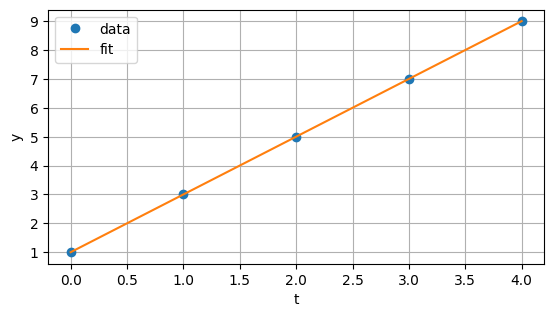

In [3]:
t = np.arange(5., dtype=float)
A = np.column_stack([np.ones_like(t), t])
y = 1 + 2*t
x, _, rank, singular = np.linalg.lstsq(A, y, rcond=None)
print('intercept, slope:', x, 'rank:', rank)
assert np.allclose(x, [1, 2])
plt.plot(t, y, 'o', label='data')
plt.plot(t, A@x, label='fit')
plt.xlabel('t'); plt.ylabel('y'); plt.legend(); plt.show()

## 安装、运行与编译

在Python 3.11或更新版本（建议3.12）的虚拟环境中，先运行 `python -m pip install -r requirements.txt`。交互阅读还可安装JupyterLab，并用 `python -m jupyterlab` 打开 `notebooks/`。

本地验证：`python -m unittest discover -s tests -v`。执行全部章节并生成PDF：`python tools/build.py --execute --pdf`。仅用已保存的执行结果重新排版：`python tools/build.py --pdf`。PDF编译还需要Pandoc和含中文组件的TeX Live（提供XeLaTeX和latexmk）。完整说明见仓库README。

生成文件为 `pdf/Least-Squares-Methods-in-Python-zh.pdf`。实际数值、图形和测试记录均提交Git；构建缓存放在 `.build/`。仓库不配置Actions或Artifact。离线构建的前提是已经安装这些依赖。

## 如何判断“学会了”

能调用函数只是第一步。你还需要检查数据和参数的量纲、残差是否有结构、雅可比是否正确、参数是否可辨识，以及失败时的停止原因。“算法停止”不等于“参数是真值”，更不等于“找到全局最优”。

## 练习与解答

练习：把上面的时间全部改为零，会发生什么？解答：此时第二列全零，斜率不能由数据确定，矩阵秩从2降到1。程序仍可返回一个最小范数解，但不能据此宣称斜率被测准。第04章将正式分析这一现象。